# PegaPlus: Human-in-the-Loop Molecular Clustering

**Course:** Machine Learning in Chemistry  
**Institution:** Indian Institute of Technology Hyderabad

| # | Team member | Roll number |
|---|---|---|
| 1 | Arvind Panda | IC24BTECH11003 |
| 2 | Ameya Khonde | IC24BTECH11009 |
| 3 | Kumar Harsh | IC24BTECH11010 |
| 4 | Himanshu Lonare | IC24BTECH11012 |

**Repository:** <https://github.com/HimaLonare/PegaPlus>

---

## 1. Abstract

PegaPlus is an educational, human-in-the-loop molecular clustering experiment on a **COX-2 dataset of 158 molecules**. Each molecule is encoded as a 1024-bit RDKit Morgan fingerprint, and molecular similarity is measured with the Tanimoto coefficient. A baseline **K-Means++** clustering (K = 8) is computed first. Human annotators then judge pairs of molecules as *Similar* or *Dissimilar*; these judgments (15 records) are converted into **must-link** (9) and **cannot-link** (6) constraints and used by a project-level **COP-KMeans-style** algorithm.

In this experiment, all 15 constraints were satisfied and 9 of 158 molecules (5.70 %) changed cluster. However, the external clustering metrics (ARI, NMI, silhouette) were **slightly lower** than for the baseline. We also checked whether the human judgments agreed with fingerprint Tanimoto similarity; with only 15 pairs, no statistically significant relationship was found. This notebook reproduces each step of the pipeline from the repository's source code and data, and reports the results honestly.

> **How this notebook relates to the repository.** The repository implements each stage as a separate script under `src/`. Those scripts print results and write CSV files. Here we re-implement the *same logic* in notebook cells (copying the algorithms without changing them), run it on the repository's own CSV files, and **assert** that the recomputed numbers match the CSV outputs saved by the scripts. The notebook only *reads* repository files; it does not overwrite them.

## 2. Introduction

**Molecular clustering.** Clustering groups molecules so that members of a cluster are more similar to each other than to molecules in other clusters. It is used for compound library analysis, diversity selection, scaffold exploration and virtual screening.

**Why molecular similarity matters.** The *similar property principle* of cheminformatics states that structurally similar molecules often (not always) have similar properties or activities. Any clustering is therefore only as meaningful as the similarity measure behind it.

**Limitations of purely unsupervised clustering.** K-Means++ only sees the numeric fingerprint vectors. It minimises Euclidean variance, tends to find compact roughly spherical groups, requires the number of clusters in advance, and cannot know which structural differences a chemist considers important. High-dimensional, sparse, binary fingerprints make this even harder.

**Why human feedback can help.** Chemists hold knowledge that is not in the fingerprint, for example which substituents or scaffolds matter. A cheap way to capture it is pairwise judgments ("these two are similar" / "these two are dissimilar"). In constrained clustering, such judgments become **must-link** and **cannot-link** constraints that the algorithm must respect.

**Project objectives**

1. Represent 158 COX-2 molecules as 1024-bit Morgan fingerprints.
2. Obtain a baseline K-Means++ clustering (K = 8).
3. Collect human pairwise feedback and convert it into constraints.
4. Run a COP-KMeans-style constrained clustering and verify constraint satisfaction.
5. Compare baseline and constrained clustering (ARI, NMI, silhouette) and analyse which molecules moved.
6. Recommend further informative pairs for human review.
7. Check the human judgments against Tanimoto similarity.

## 3. Libraries and environment

Only libraries used by the project are imported: `numpy`, `pandas` (data), `matplotlib`, `seaborn` (plots), `scikit-learn` (K-Means++, PCA, metrics), `scipy` (statistics) and `RDKit` (fingerprints and a cross-check of Tanimoto similarity).

The cell also locates the repository root so that all paths are **relative to the repository** (the notebook works whether it is opened from the repository root or from a `notebooks/` sub-folder).

In [2]:
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn, scipy
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, roc_auc_score, roc_curve)
from scipy.stats import mannwhitneyu, spearmanr

from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import rdFingerprintGenerator

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

# ---- Locate the repository root (relative paths only) ----
ROOT = Path.cwd()
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent                      # e.g. notebook stored in notebooks/
assert (ROOT / "data" / "processed").exists(), "Run this notebook from the PegaPlus repository."

DATA = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
SDF_PATH = ROOT / "reference" / "online_svm_evaluation" / "test_files" / "cox2.sdf"
LABEL_PATH = ROOT / "reference" / "online_svm_evaluation" / "test_files" / "cox2_correct.csv"

print("Repository root :", ROOT.name)
print(f"Python libs     : numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, "
      f"scipy {scipy.__version__}, RDKit {rdBase.rdkitVersion}")

# ---- Which repository files are available? ----
required = {
    "cox2_fingerprints.csv": DATA / "cox2_fingerprints.csv",
    "cox2_clustered.csv": DATA / "cox2_clustered.csv",
    "human_feedback.csv": DATA / "human_feedback.csv",
    "must_link_constraints.csv": DATA / "must_link_constraints.csv",
    "cannot_link_constraints.csv": DATA / "cannot_link_constraints.csv",
    "constrained_results.csv": DATA / "constrained_results.csv",
    "clustering_comparison.csv": RESULTS / "clustering_comparison.csv",
    "changed_molecules.csv": RESULTS / "changed_molecules.csv",
    "recommended_pairs.csv": RESULTS / "recommended_pairs.csv",
    "human_feedback_validation.csv": RESULTS / "human_feedback_validation.csv",
    "human_feedback_validation_summary.csv": RESULTS / "human_feedback_validation_summary.csv",
}
optional = {"cox2.sdf (raw molecules)": SDF_PATH, "cox2_correct.csv (raw labels)": LABEL_PATH}
for name, p in required.items():
    print(f"[{'OK' if p.exists() else 'MISSING'}] required : {name}")
for name, p in optional.items():
    print(f"[{'OK' if p.exists() else 'MISSING'}] optional : {name}")
missing = [n for n, p in required.items() if not p.exists()]
assert not missing, f"Missing required files: {missing}"

Repository root : PegaPlus
Python libs     : numpy 2.4.6, pandas 3.1.1, scikit-learn 1.9.1, scipy 1.17.1, RDKit 2026.09.2
[OK] required : cox2_fingerprints.csv
[OK] required : cox2_clustered.csv
[OK] required : human_feedback.csv
[OK] required : must_link_constraints.csv
[OK] required : cannot_link_constraints.csv
[OK] required : constrained_results.csv
[OK] required : clustering_comparison.csv
[OK] required : changed_molecules.csv
[OK] required : recommended_pairs.csv
[OK] required : human_feedback_validation.csv
[OK] required : human_feedback_validation_summary.csv
[OK] optional : cox2.sdf (raw molecules)
[OK] optional : cox2_correct.csv (raw labels)


> **Missing optional files.** In the GitHub repository, the folder `reference/` is empty (it is recorded as a Git link to another repository, and its contents were not included in the clone). The raw COX-2 files `cox2.sdf` and `cox2_correct.csv` used by `main.py` are therefore **not available**, and `main.py` cannot be re-run from a fresh clone. Instead of fabricating them, this notebook starts from the repository's saved `data/processed/cox2_fingerprints.csv` / `cox2_clustered.csv` (which `main.py` generated). If you restore the `reference/` folder, Section 5 will automatically verify the fingerprints against the SDF file.

## 4. Dataset loading and exploration

`main.py` produced two files that contain the whole dataset:

* `cox2_fingerprints.csv`: columns `FP_0 … FP_1023` (the fingerprint bits) and `reference_label` (a reference class label supplied with the COX-2 benchmark; used *only* for external evaluation, never for clustering).
* `cox2_clustered.csv`: the same columns plus `predicted_cluster` (the baseline K-Means++ assignment).

**Molecule IDs** are 1-based (row 1 = molecule 1) in the feedback and constraint files, whereas Python indices are 0-based. Constraint files carry both (`molecule_*` and `index_*`).

In [3]:
fp_df = pd.read_csv(DATA / "cox2_fingerprints.csv")
df = pd.read_csv(DATA / "cox2_clustered.csv")

FP_COLS = [c for c in df.columns if c.startswith("FP_")]
X = df[FP_COLS].to_numpy(dtype=np.uint8)           # binary fingerprint matrix (158 x 1024)
Xb = X.astype(bool)
ref = df["reference_label"].to_numpy()             # reference labels (evaluation only)
base_labels = df["predicted_cluster"].to_numpy()   # baseline K-Means++ clusters saved by main.py
N, FP_SIZE = X.shape
K = 8

print("Dataset dimensions (clustered file)   :", df.shape)
print("Dataset dimensions (fingerprint file) :", fp_df.shape)
print("Molecules x fingerprint bits          :", X.shape)
print("Fingerprint files identical?          :", bool((fp_df[FP_COLS].to_numpy() == df[FP_COLS].to_numpy()).all()))
print("Missing values in clustered file      :", int(df.isna().sum().sum()))
print("Values in fingerprint matrix          :", np.unique(X))

Dataset dimensions (clustered file)   : (158, 1026)
Dataset dimensions (fingerprint file) : (158, 1025)
Molecules x fingerprint bits          : (158, 1024)
Fingerprint files identical?          : True
Missing values in clustered file      : 0
Values in fingerprint matrix          : [0 1]


In [4]:
# Sample records (first 8 fingerprint bits + labels) - the full 1024 columns would not be readable
sample = df[FP_COLS[:8] + ["reference_label", "predicted_cluster"]].copy()
sample.index = np.arange(1, N + 1); sample.index.name = "molecule_id"
display(sample.head(8))

,FP_0,FP_1,FP_2,FP_3,FP_4,FP_5,FP_6,FP_7,reference_label,predicted_cluster
molecule_id,,,,,,,,,,
1,0,0,0,0,0,0,0,0,3,6
2,0,1,0,0,0,0,0,1,3,2
3,0,0,0,0,0,0,0,0,3,6
4,0,0,1,0,1,0,0,0,3,6
5,0,0,0,0,0,0,0,0,3,6
6,0,0,0,0,0,0,0,0,3,2
7,0,1,0,0,0,0,0,0,3,6
8,0,0,0,0,0,0,0,0,3,6


Active bits per molecule: mean=62.0, min=42, max=80
Overall fingerprint density: 0.061


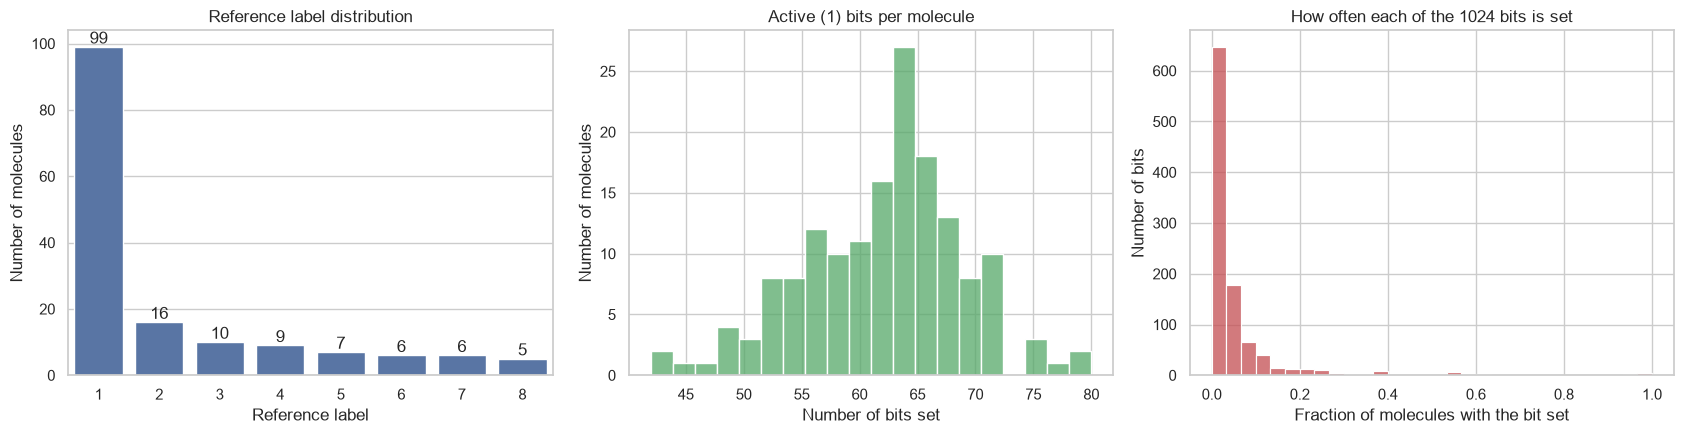

Bits never set in any molecule: 75


In [5]:
bits_on = X.sum(axis=1)
print(f"Active bits per molecule: mean={bits_on.mean():.1f}, min={bits_on.min()}, max={bits_on.max()}")
print(f"Overall fingerprint density: {X.mean():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
lab_counts = pd.Series(ref).value_counts().sort_index()
sns.barplot(x=lab_counts.index, y=lab_counts.values, ax=ax[0], color="#4C72B0")
ax[0].set(title="Reference label distribution", xlabel="Reference label", ylabel="Number of molecules")
for i, v in enumerate(lab_counts.values): ax[0].text(i, v + 1, str(v), ha="center")

sns.histplot(bits_on, bins=20, ax=ax[1], color="#55A868")
ax[1].set(title="Active (1) bits per molecule", xlabel="Number of bits set", ylabel="Number of molecules")

col_freq = X.mean(axis=0)
sns.histplot(col_freq, bins=30, ax=ax[2], color="#C44E52")
ax[2].set(title="How often each of the 1024 bits is set", xlabel="Fraction of molecules with the bit set", ylabel="Number of bits")
plt.tight_layout(); plt.show()
print("Bits never set in any molecule:", int((X.sum(axis=0) == 0).sum()))

**Observations.** The dataset has no missing values and is purely binary. The reference labels are **strongly imbalanced** (label 1 contains 99 of 158 molecules, i.e. about 63 %), which limits the maximum ARI/NMI any 8-cluster solution can reach, and makes these external metrics sensitive to small changes. Fingerprints are sparse (about 6 % of bits set per molecule, and 75 of the 1024 bits are never set). The SDF file with names/SMILES/properties is not in the repository, so no chemical property plots (e.g. molecular weight) can be produced without fabricating data.

## 5. Molecular fingerprint generation

**Morgan (circular) fingerprints.** For every atom, the algorithm collects the atom's environment up to a given *radius* (the number of bonds away), hashes each environment into an integer, and folds the integers into a fixed-length bit vector (here **1024 bits**). Two molecules that share many substructural environments share many set bits.

**Why fingerprints are useful.** They turn molecules (graphs) into fixed-length numeric vectors which standard ML algorithms and fast similarity measures can use.

**Tanimoto (Jaccard) similarity** between binary fingerprints $A$ and $B$:

$$T(A,B)=\frac{|A\cap B|}{|A\cup B|}=\frac{c}{a+b-c}$$

where $a$ and $b$ are the numbers of bits set in $A$ and $B$ and $c$ the number of bits set in both. $T=1$ means identical bit patterns; $T=0$ means no shared bits. The corresponding distance $1-T$ is the **Jaccard distance**, used for the silhouette score in this project.

**Repository settings (from `main.py`).** `rdFingerprintGenerator.GetMorganGenerator(radius=4, fpSize=1024)`. Note that the radius used in the code is **4** (a larger neighbourhood than the common default of 2). Because folding to 1024 bits can map different environments to the same bit, collisions are possible.

In [6]:
# --- Fingerprint generator with the SAME settings as main.py ---
RADIUS = 4
generator = rdFingerprintGenerator.GetMorganGenerator(radius=RADIUS, fpSize=FP_SIZE)

if SDF_PATH.exists():
    # Full re-generation exactly as in main.py, then compare with the saved CSV
    mols = [m for m in Chem.SDMolSupplier(str(SDF_PATH)) if m is not None]
    regen = np.zeros((len(mols), FP_SIZE), dtype=np.uint8)
    for i, m in enumerate(mols):
        DataStructs.ConvertToNumpyArray(generator.GetFingerprint(m), regen[i])
    print("Regenerated from SDF:", regen.shape, "| identical to saved CSV:", bool((regen == X).all()))
else:
    print("cox2.sdf is not in the repository clone -> fingerprints cannot be regenerated here.")
    print("Using the saved fingerprints produced by main.py (data/processed/cox2_fingerprints.csv).")
    print("Generator that main.py uses:", "Morgan, radius =", RADIUS, ", fpSize =", FP_SIZE)

Regenerated from SDF: (158, 1024) | identical to saved CSV: True


In [7]:
# --- Tanimoto similarity: project formula (as in src/intelligent_pair_selection.py) ---
def tanimoto_similarity(fp1, fp2):
    inter = np.sum((fp1 == 1) & (fp2 == 1))
    union = np.sum((fp1 == 1) | (fp2 == 1))
    return 0.0 if union == 0 else inter / union

# Cross-check against RDKit's own implementation by rebuilding RDKit bit vectors from the CSV rows
def to_bitvect(row):
    bv = DataStructs.ExplicitBitVect(FP_SIZE)
    bv.SetBitsFromList([int(i) for i in np.flatnonzero(row)])
    return bv

example_pairs = [(1, 2), (1, 3), (58, 63), (75, 76)]      # molecule IDs (1-based) taken from the feedback file
chk = []
for a, b in example_pairs:
    mine = tanimoto_similarity(X[a - 1], X[b - 1])
    rd = DataStructs.TanimotoSimilarity(to_bitvect(X[a - 1]), to_bitvect(X[b - 1]))
    chk.append({"molecule_1": a, "molecule_2": b, "project formula": mine, "RDKit": rd, "match": np.isclose(mine, rd)})
chk = pd.DataFrame(chk); display(chk)
assert chk["match"].all()

,molecule_1,molecule_2,project formula,RDKit,match
0,1,2,0.146341,0.146341,True
1,1,3,0.256098,0.256098,True
2,58,63,0.767123,0.767123,True
3,75,76,0.768116,0.768116,True


Pairwise Tanimoto over all 12403 unordered pairs: mean=0.190, median=0.168, min=0.045, max=0.775


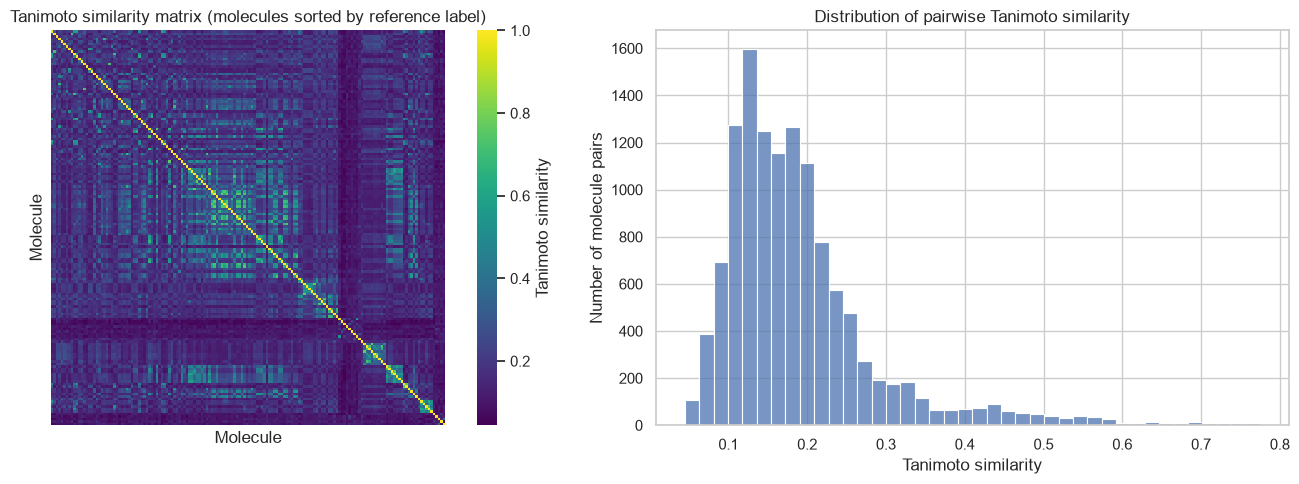

In [8]:
# Full 158 x 158 Tanimoto similarity matrix (vectorised, equivalent to the pairwise function above)
Xf = X.astype(float)
inter = Xf @ Xf.T
cnt = Xf.sum(axis=1)
union = cnt[:, None] + cnt[None, :] - inter
S = np.where(union > 0, inter / np.where(union > 0, union, 1), 0.0)
assert np.isclose(S[0, 1], tanimoto_similarity(X[0], X[1]))

iu = np.triu_indices(N, k=1)
print(f"Pairwise Tanimoto over all {len(iu[0])} unordered pairs: mean={S[iu].mean():.3f}, median={np.median(S[iu]):.3f}, "
      f"min={S[iu].min():.3f}, max={S[iu].max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order_ref = np.argsort(ref, kind="stable")
sns.heatmap(S[np.ix_(order_ref, order_ref)], cmap="viridis", ax=ax[0], square=True, cbar_kws={"label": "Tanimoto similarity"},
            xticklabels=False, yticklabels=False)
ax[0].set(title="Tanimoto similarity matrix (molecules sorted by reference label)", xlabel="Molecule", ylabel="Molecule")
sns.histplot(S[iu], bins=40, ax=ax[1], color="#4C72B0")
ax[1].set(title="Distribution of pairwise Tanimoto similarity", xlabel="Tanimoto similarity", ylabel="Number of molecule pairs")
plt.tight_layout(); plt.show()

## 6. Baseline clustering (K-Means++)

`main.py` runs

```python
KMeans(n_clusters=8, init="k-means++", n_init=20, random_state=42)
```

on the 1024-bit fingerprint matrix. **K-Means++** (Arthur & Vassilvitskii, 2007) chooses well-spread initial centres by sampling each new centre with probability proportional to its squared distance from the existing centres, which gives better and more stable results than random initialisation.

**Evaluation (same as the project):**
* **ARI** and **NMI** compare the clusters with the reference labels (external metrics). 
* **Silhouette** uses the **Jaccard distance** on the boolean fingerprints (internal metric; range −1…1, higher is better).

We re-run the K-Means++ call and check that it reproduces the saved `predicted_cluster` column exactly.

In [9]:
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=20, random_state=42)   # identical to main.py
labels_recomputed = kmeans.fit_predict(X)

print("Re-run reproduces saved baseline assignments exactly:", bool((labels_recomputed == base_labels).all()))
assert (labels_recomputed == base_labels).all()

def evaluate(labels):
    # same metrics as src/compare_clustering.py
    ari = adjusted_rand_score(ref, labels)
    nmi = normalized_mutual_info_score(ref, labels)
    sil = silhouette_score(Xb, labels, metric="jaccard") if len(np.unique(labels)) > 1 else np.nan
    return ari, nmi, sil

base_ari, base_nmi, base_sil = evaluate(base_labels)
print(f"Baseline  ARI = {base_ari:.6f}   NMI = {base_nmi:.6f}   Silhouette (Jaccard) = {base_sil:.6f}")

Re-run reproduces saved baseline assignments exactly: True
Baseline  ARI = 0.073954   NMI = 0.344067   Silhouette (Jaccard) = 0.123142


,molecule_id,reference_label,baseline_cluster
0,1,3,6
1,2,3,2
2,3,3,6
3,4,3,6
4,5,3,6
5,6,3,2
6,7,3,6
7,8,3,6
8,9,3,6
9,10,3,7


baseline_cluster,0,1,2,3,4,5,6,7
molecules,17,19,19,20,20,14,29,20


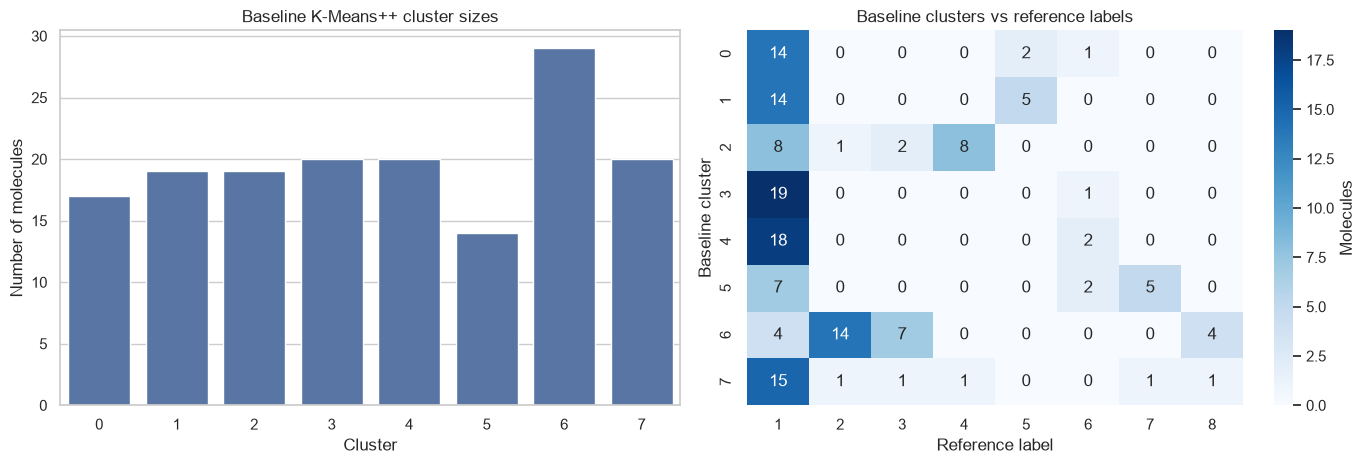

In [10]:
# Cluster assignments and sizes
assign = pd.DataFrame({"molecule_id": np.arange(1, N + 1), "reference_label": ref, "baseline_cluster": base_labels})
display(assign.head(10))
sizes = assign["baseline_cluster"].value_counts().sort_index()
display(sizes.rename("molecules").to_frame().T)

# Cluster vs reference-label contingency table
ct = pd.crosstab(assign["baseline_cluster"], assign["reference_label"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.barplot(x=sizes.index, y=sizes.values, ax=ax[0], color="#4C72B0")
ax[0].set(title="Baseline K-Means++ cluster sizes", xlabel="Cluster", ylabel="Number of molecules")
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax[1], cbar_kws={"label": "Molecules"})
ax[1].set(title="Baseline clusters vs reference labels", xlabel="Reference label", ylabel="Baseline cluster")
plt.tight_layout(); plt.show()

PCA explained variance (2 components): 18.89 %


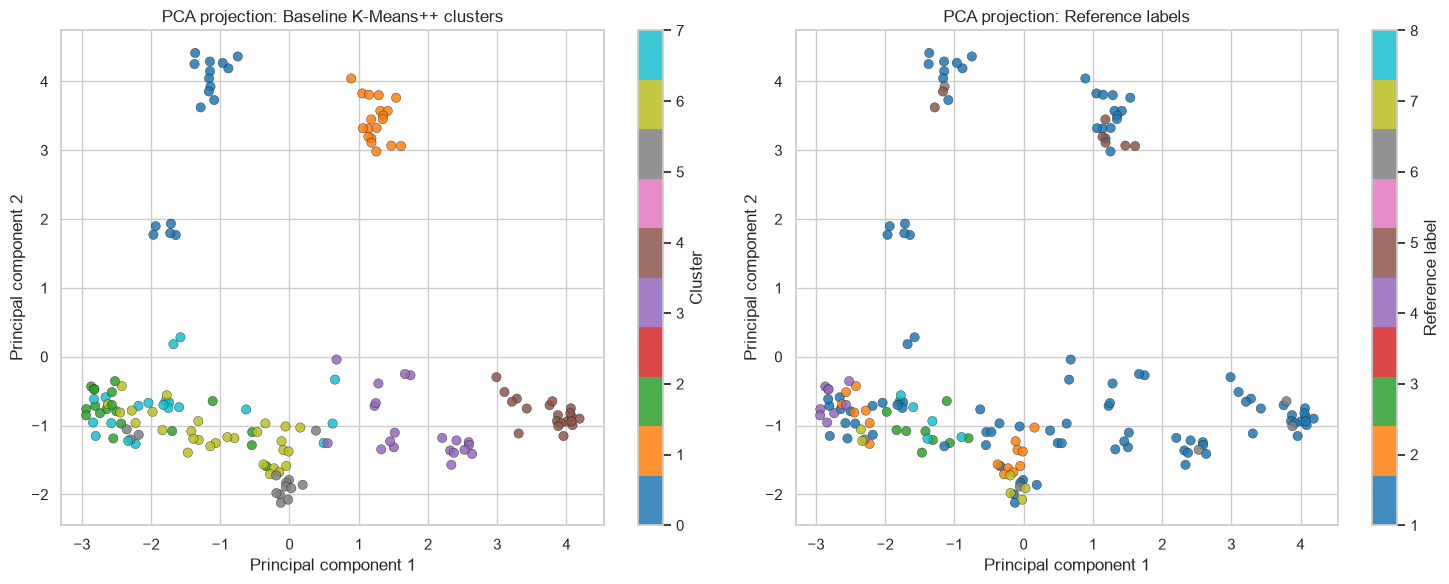

In [11]:
# 2-D PCA projection (for visualisation only; clustering used all 1024 bits)
pca = PCA(n_components=2)
Z = pca.fit_transform(X.astype(float))
print(f"PCA explained variance (2 components): {pca.explained_variance_ratio_.sum()*100:.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, lab, title, cb in [(ax[0], base_labels, "Baseline K-Means++ clusters", "Cluster"),
                          (ax[1], ref, "Reference labels", "Reference label")]:
    sc = a.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="tab10", s=45, alpha=0.85, edgecolor="k", linewidth=0.3)
    a.set(title=f"PCA projection: {title}", xlabel="Principal component 1", ylabel="Principal component 2")
    plt.colorbar(sc, ax=a, label=cb)
plt.tight_layout(); plt.show()

**Reading the baseline.** The clusters are of reasonable size (14–29 molecules), but ARI ≈ 0.074 and NMI ≈ 0.344 show that the fingerprint clusters agree only weakly with the reference labels, and silhouette ≈ 0.123 indicates overlapping, weakly separated clusters. The 2-D PCA plot captures only a small share of the variance, so apparent overlap in the plot should not be over-interpreted.

## 7. Human feedback

Annotators used a Streamlit app (`src/feedback_app.py`) to judge a pair of molecules (`molecule_1`, `molecule_2`) as:

* **Similar**: the annotator considers the two molecules structurally similar → should end up in the *same* cluster;
* **Dissimilar**: considered structurally different → should end up in *different* clusters.

The file `data/processed/human_feedback.csv` stores these records. The column `relationship` is the label used by the pipeline; `feedback` duplicates it. The columns `cluster_1`, `cluster_2`, `reference_label_*` and `timestamp` are metadata recorded by the app, and are blank for some of the early records (they are not used by the constraint engine).

In [12]:
fb = pd.read_csv(DATA / "human_feedback.csv")
print("Feedback records:", len(fb))
display(fb)
print("\nJudgment counts:"); print(fb["relationship"].value_counts().to_string())
print("\nBlank metadata cells per column:"); print(fb.isna().sum()[fb.isna().sum() > 0].to_string())
print("\n'feedback' column identical to 'relationship':", bool((fb["feedback"] == fb["relationship"]).all()))

Feedback records: 15


,molecule_1,molecule_2,relationship,cluster_1,cluster_2,reference_label_1,reference_label_2,timestamp,feedback
0,1,2,Similar,6.0,2.0,3.0,3.0,2026-11-13T18:22:20.523868,Similar
1,3,1,Dissimilar,6.0,6.0,3.0,3.0,2026-11-13T18:22:35.426621,Dissimilar
2,58,63,Similar,NaN,NaN,NaN,NaN,NaN,Similar
3,75,76,Dissimilar,NaN,NaN,NaN,NaN,NaN,Dissimilar
4,131,134,Dissimilar,NaN,NaN,NaN,NaN,NaN,Dissimilar
5,3,151,Similar,6.0,1.0,3.0,5.0,2026-11-13T23:24:12.903117,Similar
6,2,87,Similar,2.0,1.0,3.0,1.0,2026-11-13T23:31:05.938182,Similar
7,3,37,Similar,6.0,7.0,3.0,1.0,2026-11-13T23:31:14.977973,Similar
8,2,126,Dissimilar,2.0,6.0,3.0,8.0,2026-11-13T23:33:21.035317,Dissimilar
9,146,147,Similar,1.0,0.0,NaN,NaN,2026-11-14T00:11:45.040948,Similar



Judgment counts:
relationship
Similar       9
Dissimilar    6

Blank metadata cells per column:
cluster_1            3
cluster_2            3
reference_label_1    9
reference_label_2    9
timestamp            3

'feedback' column identical to 'relationship': True


## 8. Constraint generation

The logic below is copied from `src/constraint_engine.py`:

1. Cast IDs to integers and normalise the relationship text (`strip().lower()`).
2. **Invalid records** are skipped: a molecule ID outside 1…158, a molecule compared with itself, or a relationship other than *similar* / *dissimilar*.
3. Each pair is stored in **sorted order**, so (3, 1) and (1, 3) are the same pair.
4. `similar → must_link`; `dissimilar → cannot_link`.
5. **Conflicts / duplicates:** if the same pair received *both* relationships, it is reported as a *conflicting pair* and **dropped** (no constraint is generated for it). Repeated identical feedback collapses into one constraint.
6. IDs are converted to 0-based indices for the clustering step.

In [13]:
def generate_constraints(feedback_df, total_molecules):
    # Logic copied from src/constraint_engine.py
    must_link, cannot_link, invalid_records = [], [], []
    pair_relationships = {}
    for _, row in feedback_df.iterrows():
        mol1, mol2 = int(row["molecule_1"]), int(row["molecule_2"])
        relationship = str(row["relationship"]).strip().lower()
        if not (1 <= mol1 <= total_molecules) or not (1 <= mol2 <= total_molecules):
            invalid_records.append((mol1, mol2, "Invalid molecule ID")); continue
        if mol1 == mol2:
            invalid_records.append((mol1, mol2, "Self-comparison")); continue
        pair = tuple(sorted((mol1, mol2)))
        if relationship == "similar":
            constraint = "must_link"
        elif relationship == "dissimilar":
            constraint = "cannot_link"
        else:
            invalid_records.append((mol1, mol2, "Unknown relationship")); continue
        pair_relationships.setdefault(pair, set()).add(constraint)
    conflicting_pairs = []
    for pair, rels in pair_relationships.items():
        if len(rels) > 1:
            conflicting_pairs.append(pair)
        elif "must_link" in rels:
            must_link.append(pair)
        elif "cannot_link" in rels:
            cannot_link.append(pair)
    return must_link, cannot_link, conflicting_pairs, invalid_records

must_link_ids, cannot_link_ids, conflicts, invalid = generate_constraints(fb, N)

print("Total feedback records :", len(fb))
print("Must-link constraints  :", len(must_link_ids))
print("Cannot-link constraints:", len(cannot_link_ids))
print("Conflicting pairs      :", len(conflicts), conflicts)
print("Invalid records        :", len(invalid), invalid)

# Compare with the CSV files written by the repository
ml_saved = pd.read_csv(DATA / "must_link_constraints.csv")
cl_saved = pd.read_csv(DATA / "cannot_link_constraints.csv")
assert must_link_ids == list(zip(ml_saved.molecule_1, ml_saved.molecule_2))
assert cannot_link_ids == list(zip(cl_saved.molecule_1, cl_saved.molecule_2))
print("Regenerated constraints are identical to the saved constraint CSV files.")

# 0-based indices used by the clustering code
must_link = [(a - 1, b - 1) for a, b in must_link_ids]
cannot_link = [(a - 1, b - 1) for a, b in cannot_link_ids]

display(pd.concat([ml_saved.assign(type="must-link"), cl_saved.assign(type="cannot-link")], ignore_index=True)
        [["type", "molecule_1", "molecule_2", "index_1", "index_2"]])

Total feedback records : 15
Must-link constraints  : 9
Cannot-link constraints: 6
Conflicting pairs      : 0 []
Invalid records        : 0 []
Regenerated constraints are identical to the saved constraint CSV files.


,type,molecule_1,molecule_2,index_1,index_2
0,must-link,1,2,0,1
1,must-link,58,63,57,62
2,must-link,3,151,2,150
3,must-link,2,87,1,86
4,must-link,3,37,2,36
5,must-link,146,147,145,146
6,must-link,79,81,78,80
7,must-link,132,138,131,137
8,must-link,135,136,134,135
9,cannot-link,1,3,0,2


**Result.** 15 feedback records produced **9 must-link** and **6 cannot-link** constraints, with no invalid records and no conflicting pairs. Note that the constraints interact through shared molecules: molecules 1, 2 and 3 appear together in several constraints (e.g. 1 ~ 2, 1 ≁ 3, 3 ~ 37, 3 ~ 151, 2 ~ 87, 2 ≁ 126). The transitive closure of must-link constraints (e.g. 3 ~ 37 and 3 ~ 151 implies 37 ~ 151) could in principle make a cannot-link constraint infeasible, which the algorithm detects (see Section 9).

## 9. Constraint-aware clustering (COP-KMeans-style)

COP-KMeans (Wagstaff et al., 2001) is K-Means in which every point may only be assigned to a cluster that does **not violate** any constraint with points that are already assigned:

* **must-link (i, j):** i and j must be in the *same* cluster → if j is already placed, i is restricted to j's cluster;
* **cannot-link (i, j):** i and j must be in *different* clusters → i may not use a cluster that already holds j.

If no admissible cluster exists, the algorithm fails.

**Project implementation (`src/constrained_clustering.py`)** — reproduced unchanged:

1. Initial centres come from `KMeans(n_clusters=8, init="k-means++", n_init=10, random_state=42)` fitted on the data (note `n_init=10` here, versus `20` for the baseline).
2. Build must-/cannot-neighbour lists. Molecules are processed in descending order of *constraint degree* (most constrained first); ties keep the original order.
3. In each iteration, each molecule is assigned to the **nearest centre among its allowed clusters** (squared Euclidean distance); then centres are recomputed; iterate until the labels stop changing (max 100 iterations).
4. A `ValueError` is raised if must-link neighbours are already in different clusters, or if no admissible cluster remains.

**Differences from the original COP-KMeans paper (honest note):** the order of assignment is constraint-degree based rather than random/sequential; no transitive closure of constraints is pre-computed; and there is no restart if a dead end is reached; the algorithm just raises an error. This is therefore a *COP-KMeans-style educational implementation*, as the repository README also states.

In [14]:
def run_constrained_kmeans(X, must_link, cannot_link, n_clusters=8, max_iter=100):
    # Logic copied from src/constrained_clustering.py (variable names kept)
    X = X.astype(float)
    n_samples = len(X)

    # STEP 3: initial centres from K-Means++ (n_init=10, as in the script)
    centers = KMeans(n_clusters=n_clusters, init="k-means++", n_init=10, random_state=42).fit(X).cluster_centers_.copy()

    # STEP 4: constraint graph and processing order
    must_neighbors = [[] for _ in range(n_samples)]
    cannot_neighbors = [[] for _ in range(n_samples)]
    for i, j in must_link:
        must_neighbors[i].append(j); must_neighbors[j].append(i)
    for i, j in cannot_link:
        cannot_neighbors[i].append(j); cannot_neighbors[j].append(i)
    constraint_degree = [len(must_neighbors[i]) + len(cannot_neighbors[i]) for i in range(n_samples)]
    order = sorted(range(n_samples), key=lambda i: constraint_degree[i], reverse=True)

    # STEP 5: COP-KMeans loop
    labels = np.full(n_samples, -1, dtype=int)
    for iteration in range(max_iter):
        previous_labels = labels.copy()
        labels = np.full(n_samples, -1, dtype=int)
        for i in order:
            distances = np.sum((centers - X[i]) ** 2, axis=1)
            allowed = set(range(n_clusters))
            required = {labels[j] for j in must_neighbors[i] if labels[j] != -1}
            if len(required) > 1:
                raise ValueError("Incompatible must-link constraints.")
            if required:
                allowed &= required
            forbidden = {labels[j] for j in cannot_neighbors[i] if labels[j] != -1}
            allowed -= forbidden
            if not allowed:
                raise ValueError(f"No valid cluster available for molecule {i + 1}. The constraints may be infeasible.")
            labels[i] = min(allowed, key=lambda c: distances[c])
        for c in range(n_clusters):
            members = X[labels == c]
            if len(members) > 0:
                centers[c] = members.mean(axis=0)
        if np.array_equal(labels, previous_labels):
            print("Convergence reached at iteration:", iteration + 1)
            break
    return labels, constraint_degree

con_labels, degree = run_constrained_kmeans(X, must_link, cannot_link, n_clusters=K)

# Compare with the constrained assignments saved by the repository
con_saved = pd.read_csv(DATA / "constrained_results.csv")["constrained_cluster"].to_numpy()
print("Reproduces saved constrained assignments exactly:", bool((con_labels == con_saved).all()))
assert (con_labels == con_saved).all()

Convergence reached at iteration: 2
Reproduces saved constrained assignments exactly: True


In [15]:
# Constraint verification (as in the script)
must_satisfied = int(sum(con_labels[i] == con_labels[j] for i, j in must_link))
cannot_satisfied = int(sum(con_labels[i] != con_labels[j] for i, j in cannot_link))
print(f"Must-link satisfied  : {must_satisfied}/{len(must_link)}")
print(f"Cannot-link satisfied: {cannot_satisfied}/{len(cannot_link)}")

# Same check for the BASELINE clustering - how many constraints did K-Means++ already satisfy?
b_must = int(sum(base_labels[i] == base_labels[j] for i, j in must_link))
b_cannot = int(sum(base_labels[i] != base_labels[j] for i, j in cannot_link))
print(f"\nFor reference, baseline K-Means++ satisfied: must-link {b_must}/{len(must_link)}, cannot-link {b_cannot}/{len(cannot_link)}")

# Constraint-by-constraint table
rows = []
for kind, pairs in [("must-link", must_link), ("cannot-link", cannot_link)]:
    for i, j in pairs:
        ok_c = (con_labels[i] == con_labels[j]) if kind == "must-link" else (con_labels[i] != con_labels[j])
        ok_b = (base_labels[i] == base_labels[j]) if kind == "must-link" else (base_labels[i] != base_labels[j])
        rows.append({"constraint": kind, "molecule_1": i + 1, "molecule_2": j + 1,
                     "baseline clusters": f"{base_labels[i]} , {base_labels[j]}", "baseline satisfied": ok_b,
                     "constrained clusters": f"{con_labels[i]} , {con_labels[j]}", "constrained satisfied": ok_c})
cons_table = pd.DataFrame(rows); display(cons_table)

assert (must_satisfied, cannot_satisfied) == (9, 6)

Must-link satisfied  : 9/9
Cannot-link satisfied: 6/6

For reference, baseline K-Means++ satisfied: must-link 2/9, cannot-link 3/6


,constraint,molecule_1,molecule_2,baseline clusters,baseline satisfied,constrained clusters,constrained satisfied
0,must-link,1,2,"6 , 2",False,"2 , 2",True
1,must-link,58,63,"0 , 1",False,"0 , 0",True
2,must-link,3,151,"6 , 1",False,"6 , 6",True
3,must-link,2,87,"2 , 1",False,"2 , 2",True
4,must-link,3,37,"6 , 7",False,"6 , 6",True
5,must-link,146,147,"1 , 0",False,"1 , 1",True
6,must-link,79,81,"4 , 4",True,"4 , 4",True
7,must-link,132,138,"2 , 7",False,"2 , 2",True
8,must-link,135,136,"2 , 2",True,"2 , 2",True
9,cannot-link,1,3,"6 , 6",False,"2 , 6",True


In [16]:
sizes_c = pd.Series(con_labels).value_counts().sort_index()
display(pd.DataFrame({"baseline": sizes, "constrained": sizes_c}).T)
display(pd.DataFrame({"molecule_id": np.arange(1, N + 1), "baseline_cluster": base_labels, "constrained_cluster": con_labels}).head(10))

,0,1,2,3,4,5,6,7
baseline,17,19,19,20,20,14,29,20
constrained,17,17,21,21,19,14,30,19


,molecule_id,baseline_cluster,constrained_cluster
0,1,6,2
1,2,2,2
2,3,6,6
3,4,6,6
4,5,6,6
5,6,2,2
6,7,6,6
7,8,6,6
8,9,6,6
9,10,7,7


**Interpretation.** Every must-link pair ended up in one cluster and every cannot-link pair in different clusters (9/9 and 6/6). The table also shows that the unconstrained baseline satisfied only **5 of the 15** constraints (2/9 must-link, 3/6 cannot-link), so the constrained algorithm had to repair 10 violated constraints. The effect on molecule assignments is nevertheless small (Section 11).

## 10. Baseline versus constrained comparison

We compute the metrics for both labelings **from the assignments** and compare them with the values recorded in `results/clustering_comparison.csv` and with the values given in the project report.

In [17]:
con_ari, con_nmi, con_sil = evaluate(con_labels)

comparison = pd.DataFrame({
    "Metric": ["Adjusted Rand Index (ARI)", "Normalized Mutual Information (NMI)", "Silhouette Score (Jaccard)"],
    "Baseline K-Means++": [base_ari, base_nmi, base_sil],
    "Constrained (COP-KMeans-style)": [con_ari, con_nmi, con_sil],
})
comparison["Change"] = comparison["Constrained (COP-KMeans-style)"] - comparison["Baseline K-Means++"]
comparison["Relative change (%)"] = 100 * comparison["Change"] / comparison["Baseline K-Means++"]
comparison["Direction"] = np.where(comparison["Change"] < 0, "decreased", "increased")
display(comparison.style.format({"Baseline K-Means++": "{:.6f}", "Constrained (COP-KMeans-style)": "{:.6f}",
                                 "Change": "{:+.6f}", "Relative change (%)": "{:+.2f}"}).hide(axis="index"))

# ---- Verification against the repository CSV and the reported values ----
saved = pd.read_csv(RESULTS / "clustering_comparison.csv")
assert np.allclose(saved["K-Means++"], [base_ari, base_nmi, base_sil])
assert np.allclose(saved["Constrained K-Means"], [con_ari, con_nmi, con_sil])
reported = {"base": (0.073954, 0.344067, 0.123142), "con": (0.065682, 0.328182, 0.097275)}
assert np.allclose([base_ari, base_nmi, base_sil], reported["base"], atol=5e-7)
assert np.allclose([con_ari, con_nmi, con_sil], reported["con"], atol=5e-7)
print("Recomputed metrics match results/clustering_comparison.csv and the reported project values (to 6 decimals).")
print(f"Agreement between baseline and constrained clusterings (ARI): {adjusted_rand_score(base_labels, con_labels):.4f}")

Metric,Baseline K-Means++,Constrained (COP-KMeans-style),Change,Relative change (%),Direction
Adjusted Rand Index (ARI),0.073954,0.065682,-0.008272,-11.19,decreased
Normalized Mutual Information (NMI),0.344067,0.328182,-0.015885,-4.62,decreased
Silhouette Score (Jaccard),0.123142,0.097275,-0.025867,-21.01,decreased


Recomputed metrics match results/clustering_comparison.csv and the reported project values (to 6 decimals).
Agreement between baseline and constrained clusterings (ARI): 0.8700


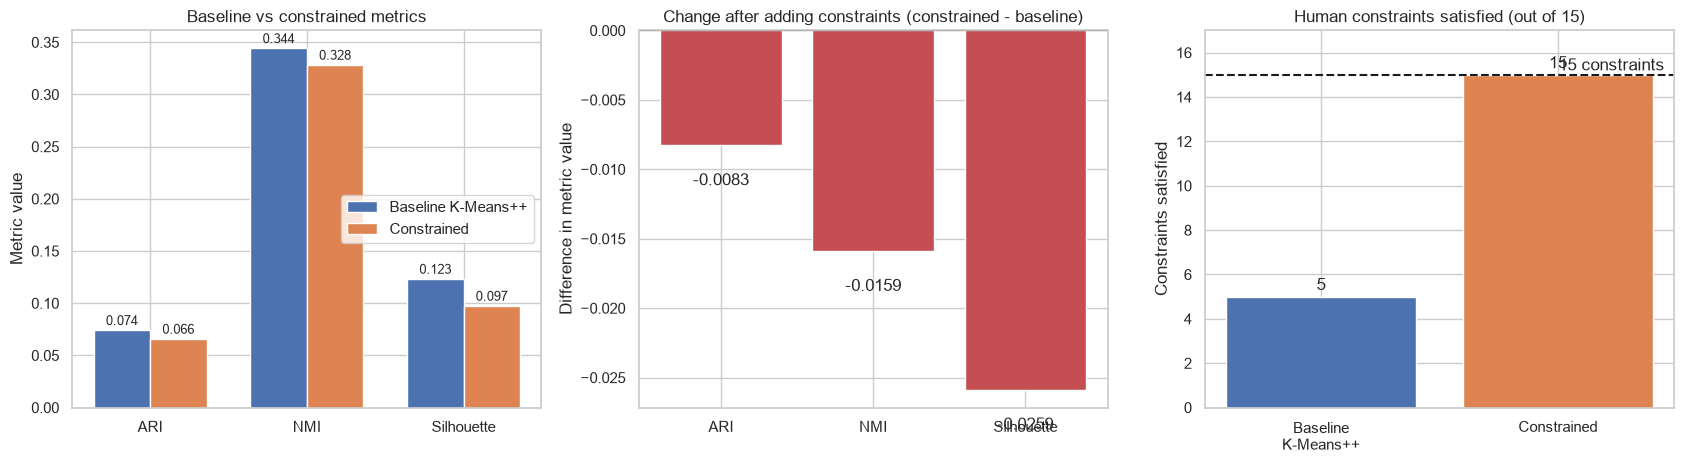

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
names = ["ARI", "NMI", "Silhouette"]
vals_b = [base_ari, base_nmi, base_sil]; vals_c = [con_ari, con_nmi, con_sil]

x = np.arange(3); w = 0.36
ax[0].bar(x - w/2, vals_b, w, label="Baseline K-Means++", color="#4C72B0")
ax[0].bar(x + w/2, vals_c, w, label="Constrained", color="#DD8452")
for i, (b, c) in enumerate(zip(vals_b, vals_c)):
    ax[0].text(i - w/2, b + 0.005, f"{b:.3f}", ha="center", fontsize=9)
    ax[0].text(i + w/2, c + 0.005, f"{c:.3f}", ha="center", fontsize=9)
ax[0].set_xticks(x); ax[0].set_xticklabels(names)
ax[0].set(title="Baseline vs constrained metrics", ylabel="Metric value"); ax[0].legend()

delta = np.array(vals_c) - np.array(vals_b)
ax[1].bar(names, delta, color=["#C44E52" if d < 0 else "#55A868" for d in delta])
ax[1].axhline(0, color="k", lw=0.8)
for i, d in enumerate(delta): ax[1].text(i, d - 0.002 if d < 0 else d + 0.001, f"{d:+.4f}", ha="center", va="top" if d < 0 else "bottom")
ax[1].set(title="Change after adding constraints (constrained - baseline)", ylabel="Difference in metric value")

ax[2].bar(["Baseline\nK-Means++", "Constrained"], [b_must + b_cannot, must_satisfied + cannot_satisfied], color=["#4C72B0", "#DD8452"])
ax[2].axhline(15, ls="--", color="k"); ax[2].text(1.45, 15.2, "15 constraints", ha="right")
ax[2].set(title="Human constraints satisfied (out of 15)", ylabel="Constraints satisfied", ylim=(0, 17))
for i, v in enumerate([b_must + b_cannot, must_satisfied + cannot_satisfied]): ax[2].text(i, v + 0.3, str(v), ha="center")
plt.tight_layout(); plt.show()

**Honest reading of the results.**

* Constraint satisfaction went to **15/15**.
* All three metrics **decreased slightly**: ARI 0.0740 → 0.0657, NMI 0.3441 → 0.3282, silhouette 0.1231 → 0.0973.
* Therefore, in this experiment, **human feedback was successfully incorporated, but it did not improve the measured clustering quality**. We do not claim the constrained clustering is better.
* Silhouette is computed from fingerprint geometry only; forcing molecules into clusters whose centres are farther away (to satisfy a constraint) naturally lowers it. ARI/NMI compare with the reference labels, which the human annotators did not see as a target; the reference labels are also very imbalanced.
* The differences are small and come from one run on 158 molecules with 15 constraints; they should not be over-interpreted as a reliable effect either way.

## 11. Human feedback impact analysis

Following `src/analyze_feedback_impact.py`, a molecule is "changed" if its constrained cluster differs from its baseline cluster. The cluster IDs are compared directly, as in the script. Both runs start from K-Means++ centres with the same `random_state=42`, so cluster IDs are aligned; the high ARI between the two clusterings (0.870, Section 10) confirms that the labels were not permuted.

In [19]:
impact = pd.DataFrame({"Molecule_ID": np.arange(1, N + 1), "Original_Cluster": base_labels, "Constrained_Cluster": con_labels})
changed = impact[impact["Original_Cluster"] != impact["Constrained_Cluster"]].copy()
pct = len(changed) / N * 100

print(f"Total molecules              : {N}")
print(f"Changed assignments          : {len(changed)}")
print(f"Unchanged assignments        : {N - len(changed)}")
print(f"Percentage of molecules changed: {pct:.2f}%")

# Which changed molecules are directly part of a human constraint?
constrained_mols = sorted({m + 1 for pair in must_link + cannot_link for m in pair})
changed["in_human_constraint"] = changed["Molecule_ID"].isin(constrained_mols)
changed["reference_label"] = ref[changed["Molecule_ID"] - 1]
changed["constraint_degree"] = [degree[m - 1] for m in changed["Molecule_ID"]]
display(changed.reset_index(drop=True))

# Verify against repository outputs / reported values
saved_changed = pd.read_csv(RESULTS / "changed_molecules.csv")
assert list(saved_changed["Molecule_ID"]) == list(changed["Molecule_ID"])
assert (len(changed), N - len(changed), round(pct, 2)) == (9, 149, 5.70)
print("\nMatches results/changed_molecules.csv and the reported values (9 changed, 149 unchanged, 5.70%).")
print(f"Changed molecules that are themselves in a human constraint: {int(changed['in_human_constraint'].sum())} of {len(changed)}")

Total molecules              : 158
Changed assignments          : 9
Unchanged assignments        : 149
Percentage of molecules changed: 5.70%


,Molecule_ID,Original_Cluster,Constrained_Cluster,in_human_constraint,reference_label,constraint_degree
0,1,6,2,True,3,2
1,37,7,6,True,1,1
2,63,1,0,True,1,1
3,76,4,3,True,1,1
4,87,1,2,True,1,1
5,134,2,7,True,4,1
6,138,7,2,True,4,1
7,147,0,1,True,5,1
8,151,1,6,True,5,1



Matches results/changed_molecules.csv and the reported values (9 changed, 149 unchanged, 5.70%).
Changed molecules that are themselves in a human constraint: 9 of 9


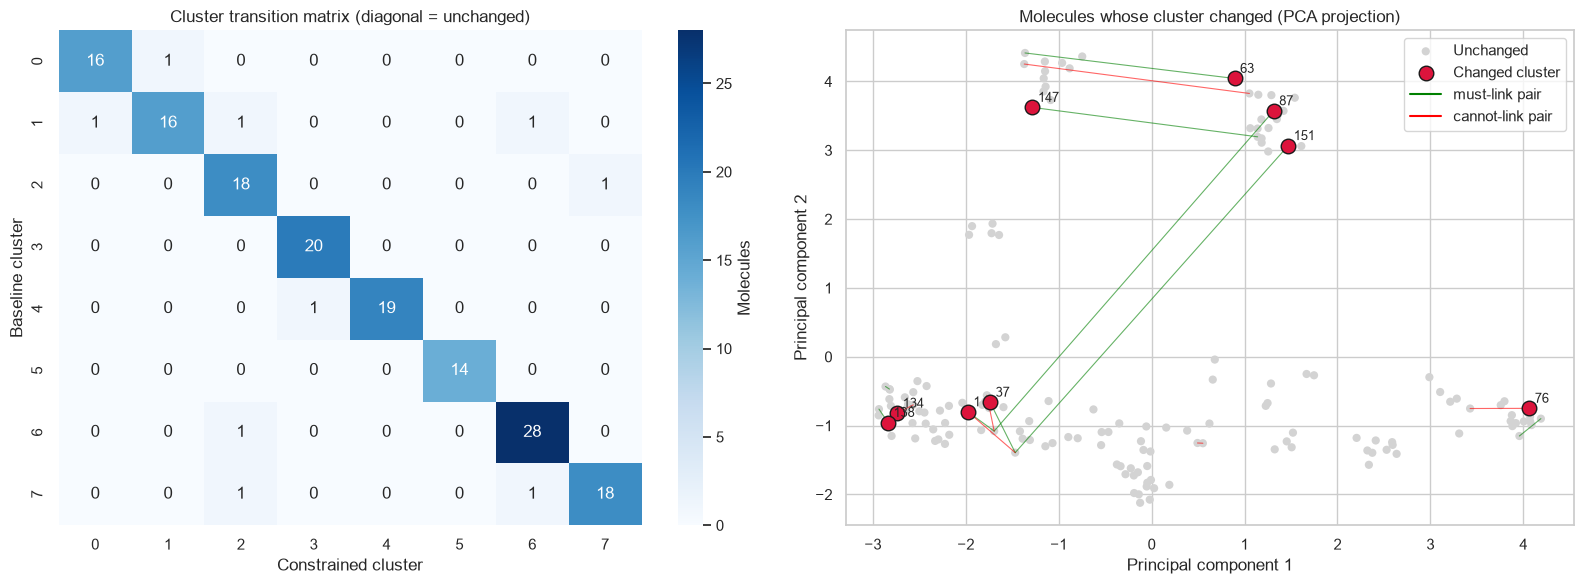

In [20]:
# Visualisations: (a) where did molecules go? (b) PCA map with changes highlighted
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

trans = pd.crosstab(impact["Original_Cluster"], impact["Constrained_Cluster"])
mask = np.eye(K, dtype=bool)
sns.heatmap(trans, annot=True, fmt="d", cmap="Blues", ax=ax[0], cbar_kws={"label": "Molecules"})
ax[0].set(title="Cluster transition matrix (diagonal = unchanged)", xlabel="Constrained cluster", ylabel="Baseline cluster")

ax[1].scatter(Z[:, 0], Z[:, 1], c="lightgrey", s=35, edgecolor="none", label="Unchanged")
ch = changed["Molecule_ID"].to_numpy() - 1
ax[1].scatter(Z[ch, 0], Z[ch, 1], c="crimson", s=110, edgecolor="k", label="Changed cluster", zorder=3)
for m in ch: ax[1].annotate(str(m + 1), (Z[m, 0], Z[m, 1]), xytext=(4, 4), textcoords="offset points", fontsize=9)
for (i, j), col in [(p, "green") for p in must_link] + [(p, "red") for p in cannot_link]:
    ax[1].plot([Z[i, 0], Z[j, 0]], [Z[i, 1], Z[j, 1]], color=col, lw=0.8, alpha=0.6)
ax[1].plot([], [], color="green", label="must-link pair"); ax[1].plot([], [], color="red", label="cannot-link pair")
ax[1].set(title="Molecules whose cluster changed (PCA projection)", xlabel="Principal component 1", ylabel="Principal component 2")
ax[1].legend(loc="best")
plt.tight_layout(); plt.show()

**Interpretation.** Only 9 of 158 molecules (5.70 %) changed cluster, so the constraints act locally. All 9 changed molecules are themselves part of a human constraint; no unconstrained molecule changed cluster in this run. The two clusterings agree strongly (ARI between them = 0.870). The transition matrix shows where the changed molecules moved. Note that 10 constraints were violated by the baseline, yet only 9 molecules moved, because a single move can repair more than one constraint.

## 12. Intelligent pair selection

**Why select pairs carefully?** Human attention is the scarce resource. There are $\binom{158}{2}=12{,}403$ possible pairs; asking about random pairs wastes feedback on uninformative cases. `src/intelligent_pair_selection.py` recommends, among pairs **not yet reviewed**, three kinds (10 each):

| Strategy | Selection rule | Purpose |
|---|---|---|
| **High Similarity** | 10 unreviewed pairs with the **highest** Tanimoto similarity | candidate must-link constraints; checks whether very similar pairs are really judged similar |
| **Low Similarity** | 10 unreviewed pairs with the **lowest** Tanimoto similarity | candidate cannot-link constraints; checks clear dissimilarity |
| **Cluster Boundary** | the 10 most Tanimoto-similar pairs that are in **different baseline clusters** | pairs where the clustering and the fingerprint similarity disagree, so a human judgment is most informative |

Pairs that appear in several strategies are kept only once (first occurrence). The code below reproduces the selection (the pair loop is vectorised using the similarity matrix `S`, which gives identical similarity values) and compares with `results/recommended_pairs.csv`.

In [21]:
# Pairs already reviewed by humans are excluded
existing_pairs = {tuple(sorted((int(a), int(b)))) for a, b in zip(fb["molecule_1"], fb["molecule_2"])}
print("Previously reviewed pairs:", len(existing_pairs))

rows = []
for i, j in combinations(range(N), 2):
    key = (i + 1, j + 1)
    if key in existing_pairs:
        continue
    rows.append({"molecule_1": i + 1, "molecule_2": j + 1,
                 "cluster_1": int(base_labels[i]), "cluster_2": int(base_labels[j]),
                 "tanimoto_similarity": S[i, j], "different_clusters": base_labels[i] != base_labels[j]})
pairs_df = pd.DataFrame(rows)
print("Total new candidate pairs:", len(pairs_df))

high = pairs_df.sort_values("tanimoto_similarity", ascending=False).head(10).assign(selection_strategy="High Similarity")
low = pairs_df.sort_values("tanimoto_similarity", ascending=True).head(10).assign(selection_strategy="Low Similarity")
boundary = (pairs_df[pairs_df["different_clusters"]].sort_values("tanimoto_similarity", ascending=False)
            .head(10).assign(selection_strategy="Cluster Boundary"))

rec = pd.concat([high, low, boundary], ignore_index=True)
rec["pair_key"] = rec.apply(lambda r: tuple(sorted((int(r.molecule_1), int(r.molecule_2)))), axis=1)
rec = rec.drop_duplicates(subset="pair_key", keep="first").drop(columns=["pair_key", "different_clusters"])
rec = rec.sort_values(["selection_strategy", "tanimoto_similarity"], ascending=[True, False]).reset_index(drop=True)

saved_rec = pd.read_csv(RESULTS / "recommended_pairs.csv")
same_pairs = (set(zip(rec.molecule_1, rec.molecule_2, rec.selection_strategy))
              == set(zip(saved_rec.molecule_1, saved_rec.molecule_2, saved_rec.selection_strategy)))
print("Recommended pairs:", len(rec), "| identical (pairs and strategies) to results/recommended_pairs.csv:", same_pairs)
assert same_pairs and np.allclose(rec.sort_values(["molecule_1","molecule_2"]).tanimoto_similarity.values,
                                  saved_rec.sort_values(["molecule_1","molecule_2"]).tanimoto_similarity.values)
print("\nRecommendations per strategy:"); print(rec["selection_strategy"].value_counts().to_string())

Previously reviewed pairs: 15
Total new candidate pairs: 12388
Recommended pairs: 27 | identical (pairs and strategies) to results/recommended_pairs.csv: True

Recommendations per strategy:
selection_strategy
High Similarity     10
Low Similarity      10
Cluster Boundary     7



--- High Similarity (top 5 of 10) ---


molecule_1,molecule_2,tanimoto_similarity,cluster_1,cluster_2
76,81,0.7681,4,4
80,81,0.7681,4,4
68,74,0.7671,0,1
69,71,0.7662,1,0
148,149,0.7639,0,1



--- Low Similarity (top 5 of 10) ---


molecule_1,molecule_2,tanimoto_similarity,cluster_1,cluster_2
2,80,0.0505,2,4
2,79,0.0500,2,4
2,42,0.0495,2,3
65,127,0.0488,3,6
5,38,0.0472,6,3



--- Cluster Boundary (top 5 of 7) ---


molecule_1,molecule_2,tanimoto_similarity,cluster_1,cluster_2
14,32,0.6716,2,6
133,138,0.6500,2,7
77,95,0.5610,1,0
71,84,0.5581,0,1
73,88,0.5517,3,4


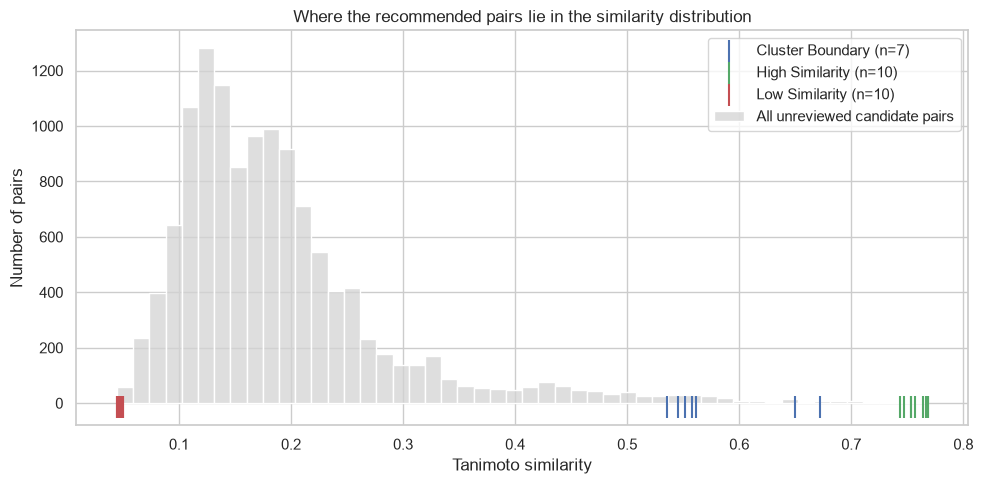

In [22]:
# Representative recommendations: top 5 of each category
for strat in ["High Similarity", "Low Similarity", "Cluster Boundary"]:
    print(f"\n--- {strat} (top 5 of {int((rec.selection_strategy == strat).sum())}) ---")
    sub = rec[rec.selection_strategy == strat].head(5)
    display(sub[["molecule_1", "molecule_2", "tanimoto_similarity", "cluster_1", "cluster_2"]].style
            .format({"tanimoto_similarity": "{:.4f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(pairs_df["tanimoto_similarity"], bins=50, color="lightgrey", ax=ax, label="All unreviewed candidate pairs")
palette = {"High Similarity": "#55A868", "Low Similarity": "#C44E52", "Cluster Boundary": "#4C72B0"}
for strat, g in rec.groupby("selection_strategy"):
    ax.scatter(g["tanimoto_similarity"], np.full(len(g), -15), marker="|", s=250, color=palette[strat], label=f"{strat} (n={len(g)})")
ax.set(title="Where the recommended pairs lie in the similarity distribution", xlabel="Tanimoto similarity", ylabel="Number of pairs")
ax.legend(); plt.tight_layout(); plt.show()

**Notes.** (i) The recommendations are *not yet answered* by humans: they are candidates for the next feedback round, so we make no claim about their outcome. (ii) The *high-similarity* and *cluster-boundary* sets overlap (a very similar pair that is split across clusters qualifies for both); such a pair is kept once under the first strategy, which is why 27 rather than 30 pairs are recommended (10 high, 10 low, 7 boundary). (iii) The selection is a simple heuristic and does not use model uncertainty or expected information gain, which would be natural extensions.

## 13. Human feedback validation

**Question.** Do human *Similar* / *Dissimilar* judgments agree with fingerprint Tanimoto similarity? If humans and fingerprints agreed, *Similar* pairs would have higher Tanimoto similarity. Following `src/validate_human_feedback.py`:

* **Mann–Whitney U test** (one-sided, `alternative="greater"`): are Tanimoto values of *Similar* pairs stochastically greater than those of *Dissimilar* pairs?
* **ROC-AUC:** how well does Tanimoto similarity rank *Similar* above *Dissimilar* (0.5 = chance, 1 = perfect)?
* **Spearman correlation** between the binary label (Similar = 1) and Tanimoto similarity.

In [23]:
# Normalise feedback as in validate_human_feedback.py
v = fb.copy()
v["relationship"] = v["relationship"].astype(str).str.strip().str.capitalize()
v = v[v["relationship"].isin(["Similar", "Dissimilar"])]
v = v[v["molecule_1"].between(1, N) & v["molecule_2"].between(1, N)]

val = pd.DataFrame({
    "molecule_1": v["molecule_1"].astype(int).values,
    "molecule_2": v["molecule_2"].astype(int).values,
    "human_feedback": v["relationship"].values,
    "tanimoto_similarity": [tanimoto_similarity(X[a - 1], X[b - 1]) for a, b in zip(v["molecule_1"], v["molecule_2"])],
})
display(val.style.format({"tanimoto_similarity": "{:.4f}"}))

sim_scores = val.loc[val.human_feedback == "Similar", "tanimoto_similarity"].to_numpy()
dis_scores = val.loc[val.human_feedback == "Dissimilar", "tanimoto_similarity"].to_numpy()

summary = pd.DataFrame({
    "Group": ["Similar", "Dissimilar"],
    "Count": [len(sim_scores), len(dis_scores)],
    "Mean": [sim_scores.mean(), dis_scores.mean()],
    "Median": [np.median(sim_scores), np.median(dis_scores)],
    "Min": [sim_scores.min(), dis_scores.min()],
    "Max": [sim_scores.max(), dis_scores.max()],
})
display(summary.style.format({c: "{:.4f}" for c in ["Mean", "Median", "Min", "Max"]}).hide(axis="index"))

,molecule_1,molecule_2,human_feedback,tanimoto_similarity
0,1,2,Similar,0.1463
1,3,1,Dissimilar,0.2561
2,58,63,Similar,0.7671
3,75,76,Dissimilar,0.7681
4,131,134,Dissimilar,0.7746
5,3,151,Similar,0.0450
6,2,87,Similar,0.0481
7,3,37,Similar,0.0481
8,2,126,Dissimilar,0.0467
9,146,147,Similar,0.7429


Group,Count,Mean,Median,Min,Max
Similar,9,0.4491,0.7237,0.0450,0.7671
Dissimilar,6,0.5502,0.7278,0.0467,0.7746


In [24]:
# Statistical tests (same calls as the project script)
mw = mannwhitneyu(sim_scores, dis_scores, alternative="greater")
y_true = (val["human_feedback"] == "Similar").astype(int)
auc = roc_auc_score(y_true, val["tanimoto_similarity"])
rho, rho_p = spearmanr(y_true, val["tanimoto_similarity"])

stats_tbl = pd.DataFrame({
    "Statistic": ["Similar judgments", "Dissimilar judgments", "Mean Tanimoto (Similar)", "Mean Tanimoto (Dissimilar)",
                  "Mann-Whitney U", "Mann-Whitney p-value (one-sided, greater)", "ROC-AUC", "Spearman correlation", "Spearman p-value"],
    "Value": [len(sim_scores), len(dis_scores), sim_scores.mean(), dis_scores.mean(), mw.statistic, mw.pvalue, auc, rho, rho_p],
})
display(stats_tbl.style.format({"Value": "{:.6f}"}).hide(axis="index"))

# Verify against the reported values and the repository CSVs
exp = dict(ms=0.449137, md=0.550190, U=22.0, p=0.741754, auc=0.407407, rho=-0.157626, rho_p=0.574765)
assert (len(sim_scores), len(dis_scores)) == (9, 6)
assert np.isclose(sim_scores.mean(), exp["ms"], atol=5e-7) and np.isclose(dis_scores.mean(), exp["md"], atol=5e-7)
assert np.isclose(mw.statistic, exp["U"]) and np.isclose(mw.pvalue, exp["p"], atol=5e-7)
assert np.isclose(auc, exp["auc"], atol=5e-7) and np.isclose(rho, exp["rho"], atol=5e-7) and np.isclose(rho_p, exp["rho_p"], atol=5e-7)
saved_val = pd.read_csv(RESULTS / "human_feedback_validation.csv")
assert np.allclose(saved_val["tanimoto_similarity"], val["tanimoto_similarity"])
print("All validation statistics match the reported project values and results/human_feedback_validation.csv.")

Statistic,Value
Similar judgments,9.000000
Dissimilar judgments,6.000000
Mean Tanimoto (Similar),0.449137
Mean Tanimoto (Dissimilar),0.550190
Mann-Whitney U,22.000000
"Mann-Whitney p-value (one-sided, greater)",0.741753
ROC-AUC,0.407407
Spearman correlation,-0.157626
Spearman p-value,0.574765


All validation statistics match the reported project values and results/human_feedback_validation.csv.


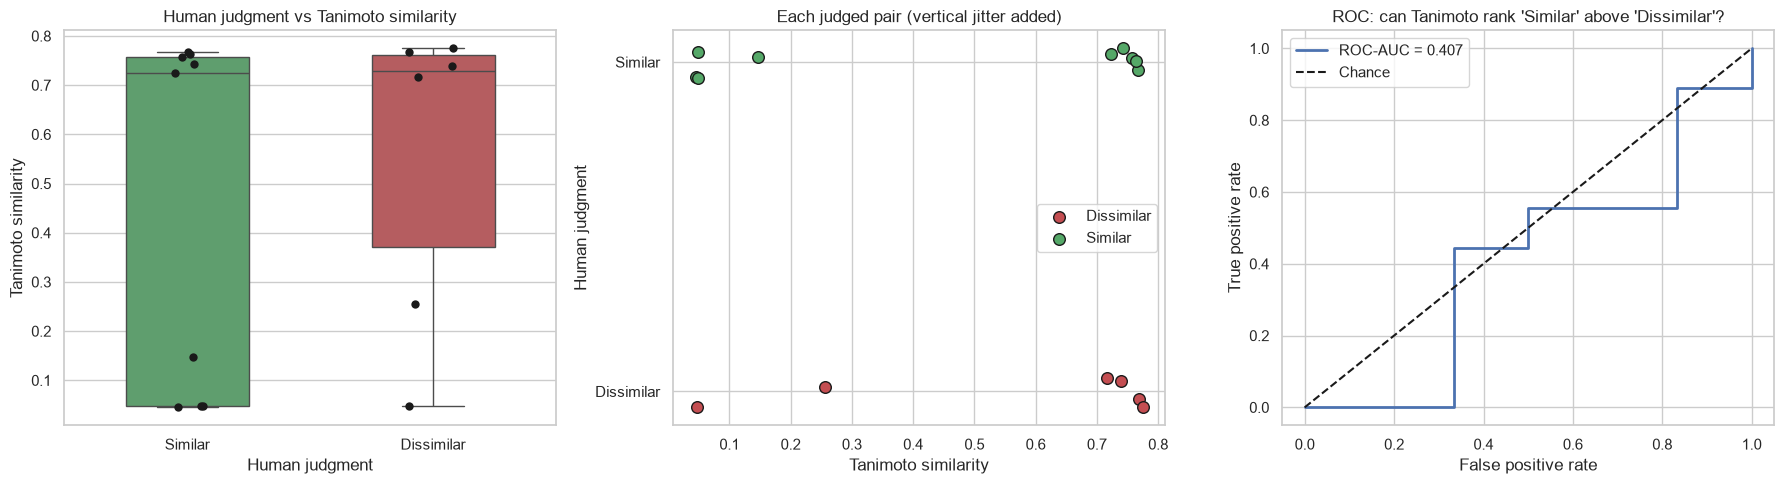

Pairs judged 'Dissimilar' with Tanimoto >= 0.7 : 4 of 6
Pairs judged 'Similar'   with Tanimoto <= 0.1 : 3 of 9


In [25]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

pal = {"Similar": "#55A868", "Dissimilar": "#C44E52"}
sns.boxplot(data=val, x="human_feedback", y="tanimoto_similarity", order=["Similar", "Dissimilar"], palette=pal, ax=ax[0], width=0.5)
sns.stripplot(data=val, x="human_feedback", y="tanimoto_similarity", order=["Similar", "Dissimilar"], color="k", size=6, ax=ax[0])
ax[0].set(title="Human judgment vs Tanimoto similarity", xlabel="Human judgment", ylabel="Tanimoto similarity")

for k, g in val.groupby("human_feedback"):
    ax[1].scatter(g["tanimoto_similarity"], np.full(len(g), 1 if k == "Similar" else 0) + np.random.default_rng(0).uniform(-0.05, 0.05, len(g)),
                  s=70, color=pal[k], edgecolor="k", label=k)
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["Dissimilar", "Similar"])
ax[1].set(title="Each judged pair (vertical jitter added)", xlabel="Tanimoto similarity", ylabel="Human judgment"); ax[1].legend()

fpr, tpr, _ = roc_curve(y_true, val["tanimoto_similarity"])
ax[2].plot(fpr, tpr, lw=2, label=f"ROC-AUC = {auc:.3f}"); ax[2].plot([0, 1], [0, 1], "k--", label="Chance")
ax[2].set(title="ROC: can Tanimoto rank 'Similar' above 'Dissimilar'?", xlabel="False positive rate", ylabel="True positive rate"); ax[2].legend()
plt.tight_layout(); plt.show()

print("Pairs judged 'Dissimilar' with Tanimoto >= 0.7 :", int((dis_scores >= 0.7).sum()), "of", len(dis_scores))
print("Pairs judged 'Similar'   with Tanimoto <= 0.1 :", int((sim_scores <= 0.1).sum()), "of", len(sim_scores))

**Cautious interpretation.**

* The mean Tanimoto of *Similar* pairs (0.449) is actually **lower** than that of *Dissimilar* pairs (0.550); ROC-AUC = 0.407 (< 0.5) and Spearman ρ = −0.158.
* None of this is statistically significant (Mann–Whitney one-sided p = 0.742; Spearman p = 0.575). So the data show **no evidence** of a positive relationship between these human judgments and Morgan-fingerprint Tanimoto similarity.
* This **does not prove the human feedback is wrong**. With only 9 + 6 = 15 pairs the test has very little power; the Similar group's distribution is wide (min ≈ 0.045, max ≈ 0.767), and a *non-significant* result is not evidence of *no* relationship.
* More importantly, the human judgments and Tanimoto similarity may measure different things. A chemist may judge by scaffold, pharmacophore or functional-group arrangement, which a hashed radius-4 fingerprint does not capture well, and a pair of structurally similar molecules can still be judged "dissimilar" because of a key substituent.
* The pattern is bimodal rather than a clean shift: 4 of the 6 *Dissimilar* pairs have Tanimoto ≥ 0.7, while 3 of the 9 *Similar* pairs have Tanimoto ≤ 0.1. These specific pairs would be worth re-examining chemically with the structures in hand (the SDF file is not available here). We also have no estimate of inter-annotator agreement.

## 14. Discussion and limitations

**Why can all constraints be satisfied while the external metrics decrease?**
Constraints and metrics measure different things. Constraint satisfaction checks 15 specific pairs. ARI and NMI measure agreement with a *reference labelling* that the annotators never saw, and silhouette measures geometric compactness in fingerprint space. A constraint may ask the algorithm to place two molecules in a cluster whose centre is farther from one of them (lower silhouette) or to separate two molecules that share a reference label (lower ARI/NMI). Our validation also shows the human judgments are not aligned with Tanimoto similarity in this sample, so honouring them can legitimately move the clustering away from the fingerprint geometry.

**Small feedback sample.** 15 pairs (9 must-link, 6 cannot-link) touch only a small portion of the 158 molecules, giving results from a single run with fixed `random_state=42`. We did not estimate variability across random seeds or across annotators; differences of 0.01–0.03 in the metrics should be treated as preliminary.

**Fingerprint / Tanimoto limitations.** Morgan fingerprints are folded to 1024 bits (collisions), are count-agnostic in this binary form, ignore 3-D shape and conformation, and radius 4 produces many large, specific environments. Tanimoto similarity depends on the number of set bits and can be dominated by molecule size. Euclidean K-Means on binary vectors is also not the same geometry as Tanimoto/Jaccard, whereas silhouette is evaluated with the Jaccard distance. This mismatch between the clustering objective and the evaluation measure is itself a possible reason for the metric changes.

**Structural similarity ≠ biological activity.** Morgan/Tanimoto similarity captures structural overlap only. Two structurally similar molecules can have very different COX-2 activity (activity cliffs), and structurally different molecules can be equally active. The reference labels are class labels that come with the benchmark, and agreement with them is not proof of chemical or biological validity.

**Limitations of the COP-KMeans-style implementation.** (i) Greedy, order-dependent assignment (most-constrained first); (ii) no transitive-closure pre-processing, no restarts: infeasible constraint sets simply raise an error; (iii) constraints are hard, so noisy or inconsistent feedback cannot be down-weighted; (iv) Euclidean distance on binary vectors; (v) constraints influence only the assignments, not a learned metric; (vi) initial centres from unconstrained K-Means++ bias the result towards the baseline.

**Other repository observations (for transparency).** `reference/` is empty in the clone, so `main.py` cannot be re-run; there is no `requirements.txt`; the README mentions a `notebooks/` folder that does not exist; the virtual environment `.venv/` is committed to Git; the first few feedback rows lack metadata; and `cluster_1/cluster_2` in the feedback file reflect the clustering at the time of each judgment.

**Potential improvements.** Collect substantially more feedback (and from several chemists, to measure agreement); use Tanimoto/Jaccard-based clustering (e.g. K-Medoids, Butina, hierarchical, spectral) or learn a metric from the constraints; use soft constraints (PCKMeans, MPCKMeans) and noise-robust methods; actively select pairs by uncertainty; try other fingerprints (radius 2, counts, FCFP, MACCS) and 3-D/pharmacophore descriptors; repeat over seeds and report confidence intervals; add an evaluation with held-out constraints or activity data.

## 15. Conclusion

We implemented and reproduced a full human-in-the-loop clustering pipeline on 158 COX-2 molecules: 1024-bit Morgan fingerprints, a K-Means++ baseline (K = 8), conversion of 15 pairwise human judgments into 9 must-link and 6 cannot-link constraints, a COP-KMeans-style constrained clustering, comparison and impact analysis, informative pair recommendation, and a statistical check of the feedback against Tanimoto similarity. All recomputed values match the repository outputs and the reported results.

**Main findings**

| Finding | Result |
|---|---|
| Constraints satisfied | 15 / 15 (must-link 9/9, cannot-link 6/6) |
| Molecules whose cluster changed | 9 of 158 (5.70 %); 149 unchanged |
| ARI | 0.073954 → 0.065682 (decreased) |
| NMI | 0.344067 → 0.328182 (decreased) |
| Silhouette (Jaccard) | 0.123142 → 0.097275 (decreased) |
| Human feedback vs Tanimoto | mean 0.449 (Similar) vs 0.550 (Dissimilar); U = 22.0, p = 0.742; ROC-AUC = 0.407; Spearman ρ = −0.158, p = 0.575: not significant |

**Take-away.** Human feedback was successfully incorporated and every constraint was satisfied, but in this experiment the external clustering metrics decreased slightly. The feedback validation did not show a statistically significant relationship with Tanimoto similarity; given the very small sample this neither confirms nor refutes the quality of the human judgments. The project's value is the working end-to-end framework, which can be scaled up with more feedback, additional annotators and better similarity measures.

## 16. References

1. Wagstaff, K., Cardie, C., Rogers, S., & Schrödl, S. (2001). Constrained K-means clustering with background knowledge. In *Proceedings of the Eighteenth International Conference on Machine Learning (ICML 2001)*, Williams College, Williamstown, MA, USA, pp. 577–584. Morgan Kaufmann.
2. Arthur, D., & Vassilvitskii, S. (2007). k-means++: The advantages of careful seeding. In *Proceedings of the 18th Annual ACM-SIAM Symposium on Discrete Algorithms (SODA '07)*, pp. 1027–1035. Society for Industrial and Applied Mathematics. https://doi.org/10.1137/1.9781611972788.1
3. Tanimoto, T. T. (1958). *An Elementary Mathematical Theory of Classification and Prediction*. IBM Internal Report, 17 November 1958. (Unpublished internal report; the coefficient is more accessibly described in Rogers & Tanimoto (1960), below.)
4. Rogers, D. J., & Tanimoto, T. T. (1960). A computer program for classifying plants. *Science*, 132(3434), 1115–1118.
5. Morgan, H. L. (1965). The generation of a unique machine description for chemical structures: a technique developed at Chemical Abstracts Service. *Journal of Chemical Documentation*, 5(2), 107–113.
6. Rogers, D., & Hahn, M. (2010). Extended-connectivity fingerprints. *Journal of Chemical Information and Modeling*, 50(5), 742–754.
7. RDKit: Open-source cheminformatics. https://www.rdkit.org
8. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.

*Bibliographic note: items 1 and 2 were checked against DBLP/the publisher DOI record; the Tanimoto 1958 report is an internal IBM document that is widely cited but not publicly archived like a journal article. Items 4–6 and 8 were not re-checked online during preparation; please verify against the publisher pages before final submission.*